In [16]:
%load_ext autoreload
%autoreload 2

import numpy as np
import time
from py_files.experiment_stats import (stat_vs_params)
from py_files.functions import (calculate_barlet_values, calculate_capon_values, get_sin_signal, get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix, calculate_full_barlet_values,)
from py_files.configs.config import init_rng, restart_rng
import py_files.configs.config as cfg
import py_files.configs.comon as comon
from py_files.plot_scrip import plot_variance_vs_param, plot_mean_vs_param
import os
origin_config = init_rng()
origin_config["realosation_count"] = 200
sin_signal = get_sin_signal
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs1["main_seed"] =99
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()
    
        
end_time = time.perf_counter()
delta_time = end_time - start_time
mean_barlett_vs_f = stat_vs_params(config_params=config_parametrs1,
                                   energy_func=calculate_barlet_values,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = cfg.FREQ_VALUES,
                                   stiring_func = calculate_stiring_matrix,
                                   stat_func = np.mean,
                                   is_CRN = False
                                   )

mean_barlett_vs_f_complex = stat_vs_params(config_params = config_parametrs2,
                                   energy_func = calculate_full_barlet_values,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = cfg.FREQ_VALUES,
                                   stiring_func = calculate_complex_stiring_matrix,
                                   stat_func = np.mean,
                                   is_CRN = False)

delta_var = np.abs(np.array(mean_barlett_vs_f_complex) - np.array(mean_barlett_vs_f))
end_time = time.perf_counter()

delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Гц', ylabel='$\\mathbb{E}[\\varepsilon]$, $град$'>)

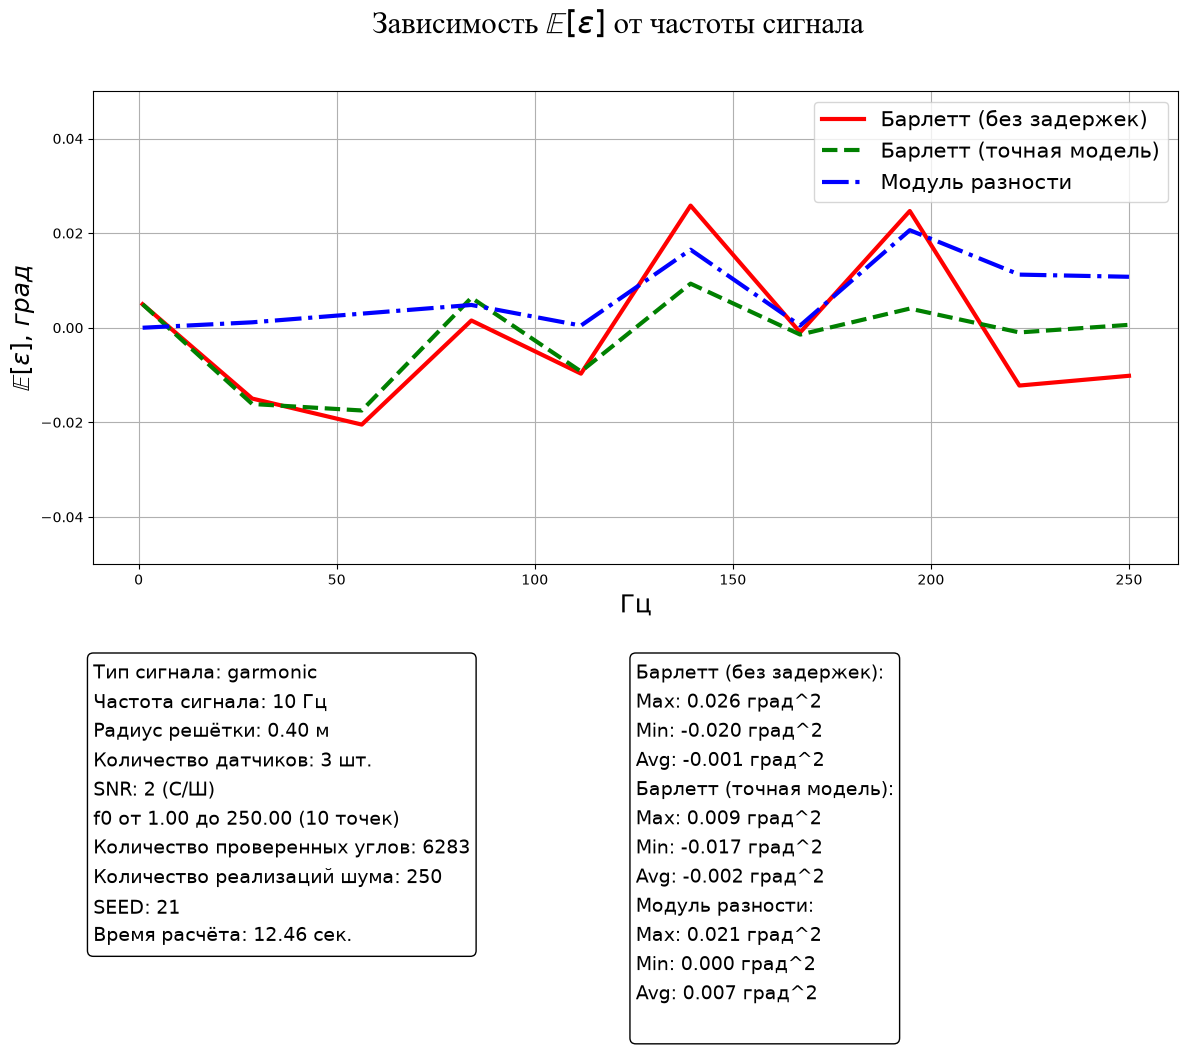

In [ ]:
plot_mean_vs_param(dict_values = {"Барлетт (без задержек)": mean_barlett_vs_f,
                                      "Барлетт (точная модель)": mean_barlett_vs_f_complex,
                                      "Модуль разности": delta_var},

                       config_params = origin_config.copy(),
                       parametr_values = cfg.FREQ_VALUES,
                       parametr_name = "f0",
                       delta_time = delta_time,
                       ylim = (-0.05*comon.CONST_RADIAN, 0.05*comon.CONST_RADIAN),
                       type_signal = "garmonic"
                       )